# Stroke Prediction Classification Pipeline

End-to-end binary classification workflow on `healthcare-dataset-stroke-data.csv` using the reference preprocessing methods, classification models, and evaluation metrics.

## 1. Importing Libraries and Configuration

Import the required data manipulation, visualization, preprocessing, model training, and evaluation modules, and configure global display and random seed settings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, ExtraTreesClassifier
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

Libraries imported and configuration set.


## 2. Exploratory Data Analysis (EDA)

Load the dataset, inspect dimensions, column data types, non-null counts, summary statistics, missing values, and duplicate records.

In [2]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["id"].duplicated().sum())
print("\nData types and non-null counts:")
print(df.info())
print("\nFirst 5 rows:")
print(df.head())
print("\nSummary statistics (numerical):")
print(df.describe())
print("\nSummary statistics (categorical):")
print(df.describe(include="object"))

Shape: 5110 rows, 12 columns
Duplicate rows: 0
Duplicate IDs: 0

Column Data Types & Non-Null Counts:
  id                 | dtype: int64    | non-null: 5110/5110 | nulls: 0
  gender             | dtype: object   | non-null: 5110/5110 | nulls: 0
  age                | dtype: float64  | non-null: 5110/5110 | nulls: 0
  hypertension       | dtype: int64    | non-null: 5110/5110 | nulls: 0
  heart_disease      | dtype: int64    | non-null: 5110/5110 | nulls: 0
  ever_married       | dtype: object   | non-null: 5110/5110 | nulls: 0
  work_type          | dtype: object   | non-null: 5110/5110 | nulls: 0
  Residence_type     | dtype: object   | non-null: 5110/5110 | nulls: 0
  avg_glucose_level  | dtype: float64  | non-null: 5110/5110 | nulls: 0
  bmi                | dtype: float64  | non-null: 4909/5110 | nulls: 201
  smoking_status     | dtype: object   | non-null: 5110/5110 | nulls: 0
  stroke             | dtype: int64    | non-null: 5110/5110 | nulls: 0


### 2.1 Numerical Distributions: Histograms and Boxplots

Visualize the distribution shape, skewness, and potential outliers for key continuous features (`age`, `avg_glucose_level`, and `bmi`).

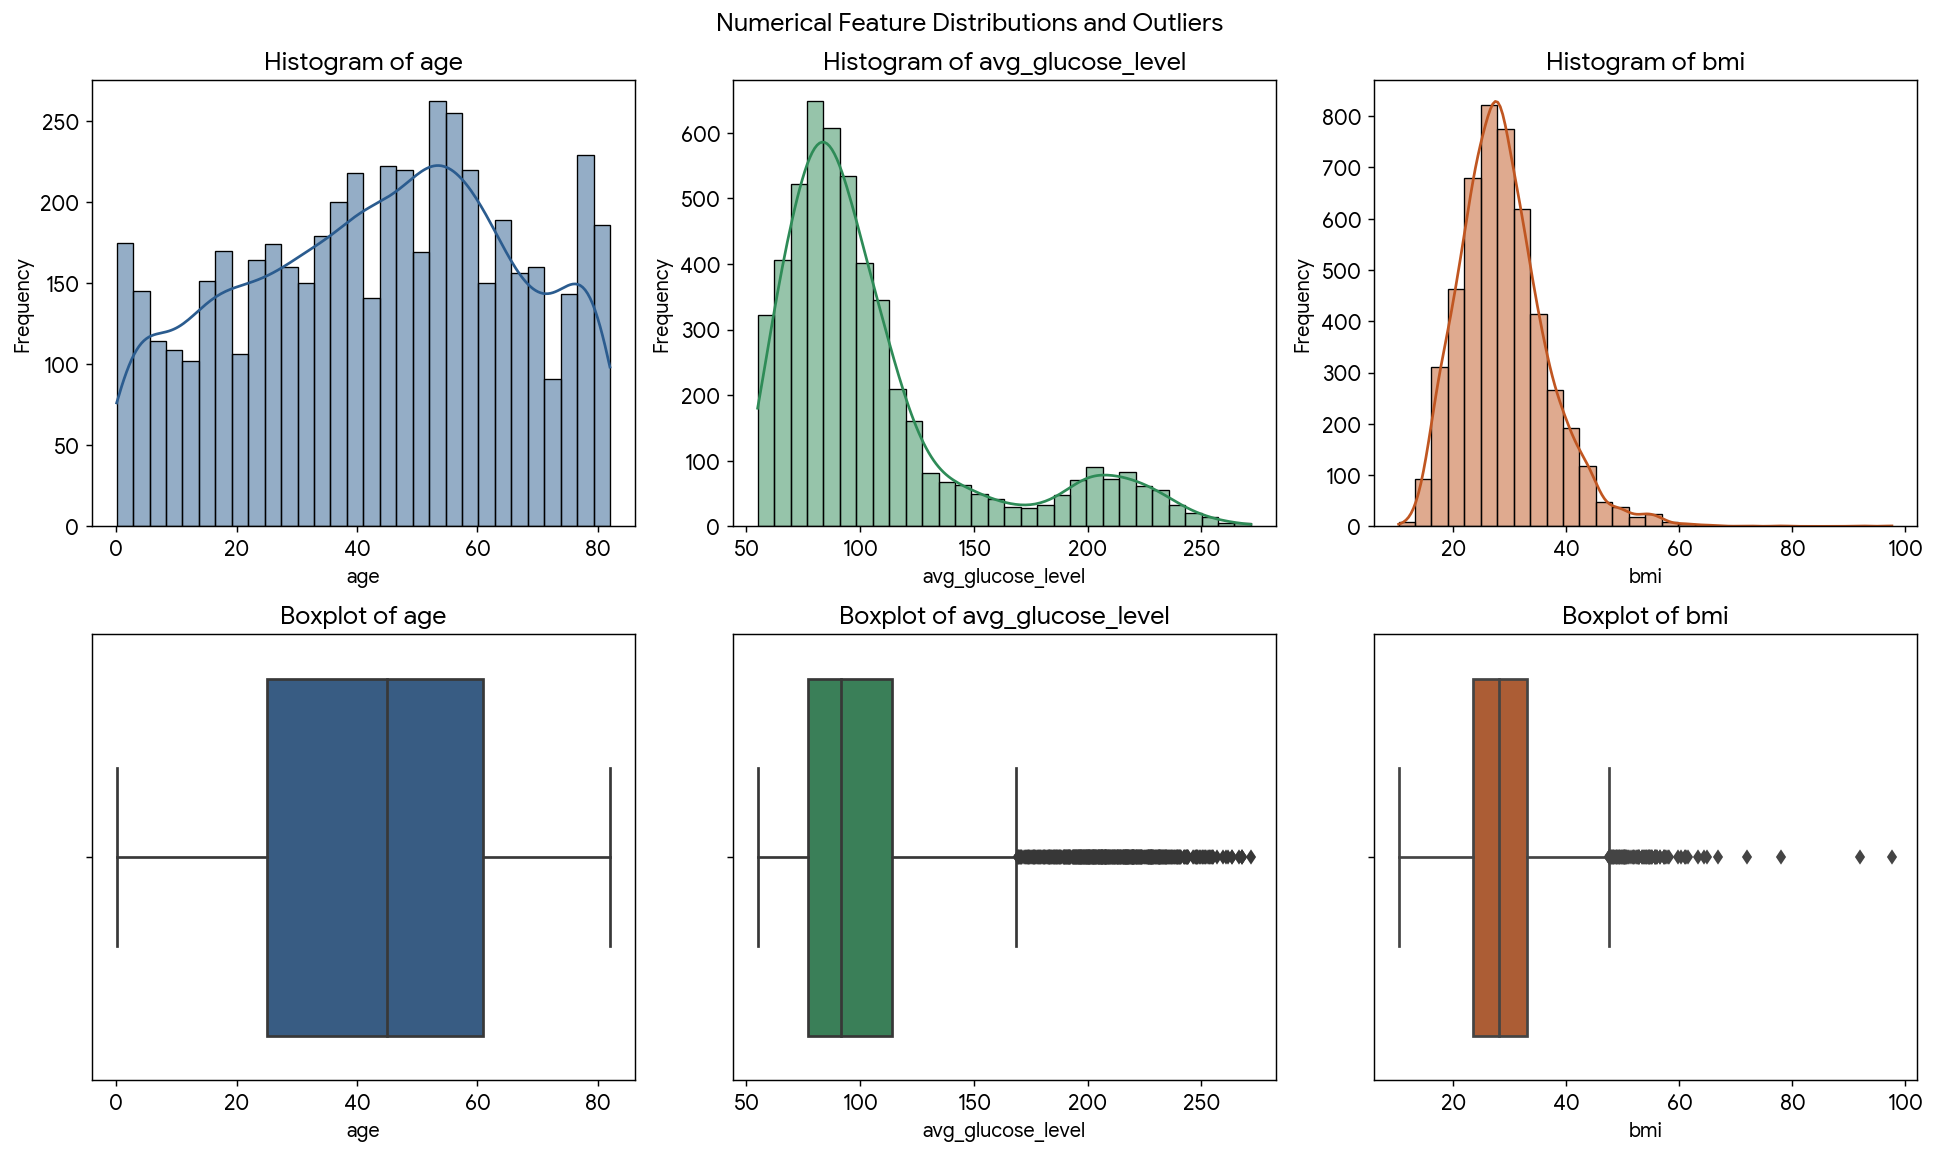

In [3]:
num_cols = ["age", "avg_glucose_level", "bmi"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for idx, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=axes[0, idx])
    axes[0, idx].set_title(f"Histogram of {col}")
    axes[0, idx].set_xlabel(col)
    axes[0, idx].set_ylabel("Frequency")

    sns.boxplot(x=df[col].dropna(), ax=axes[1, idx])
    axes[1, idx].set_title(f"Boxplot of {col}")
    axes[1, idx].set_xlabel(col)

plt.suptitle("Numerical Feature Distributions and Outliers", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.2 Categorical Counts and Correlation Heatmap

Examine category frequencies across categorical/binary variables (including target class balance) and inspect linear correlations among numerical and binary features.

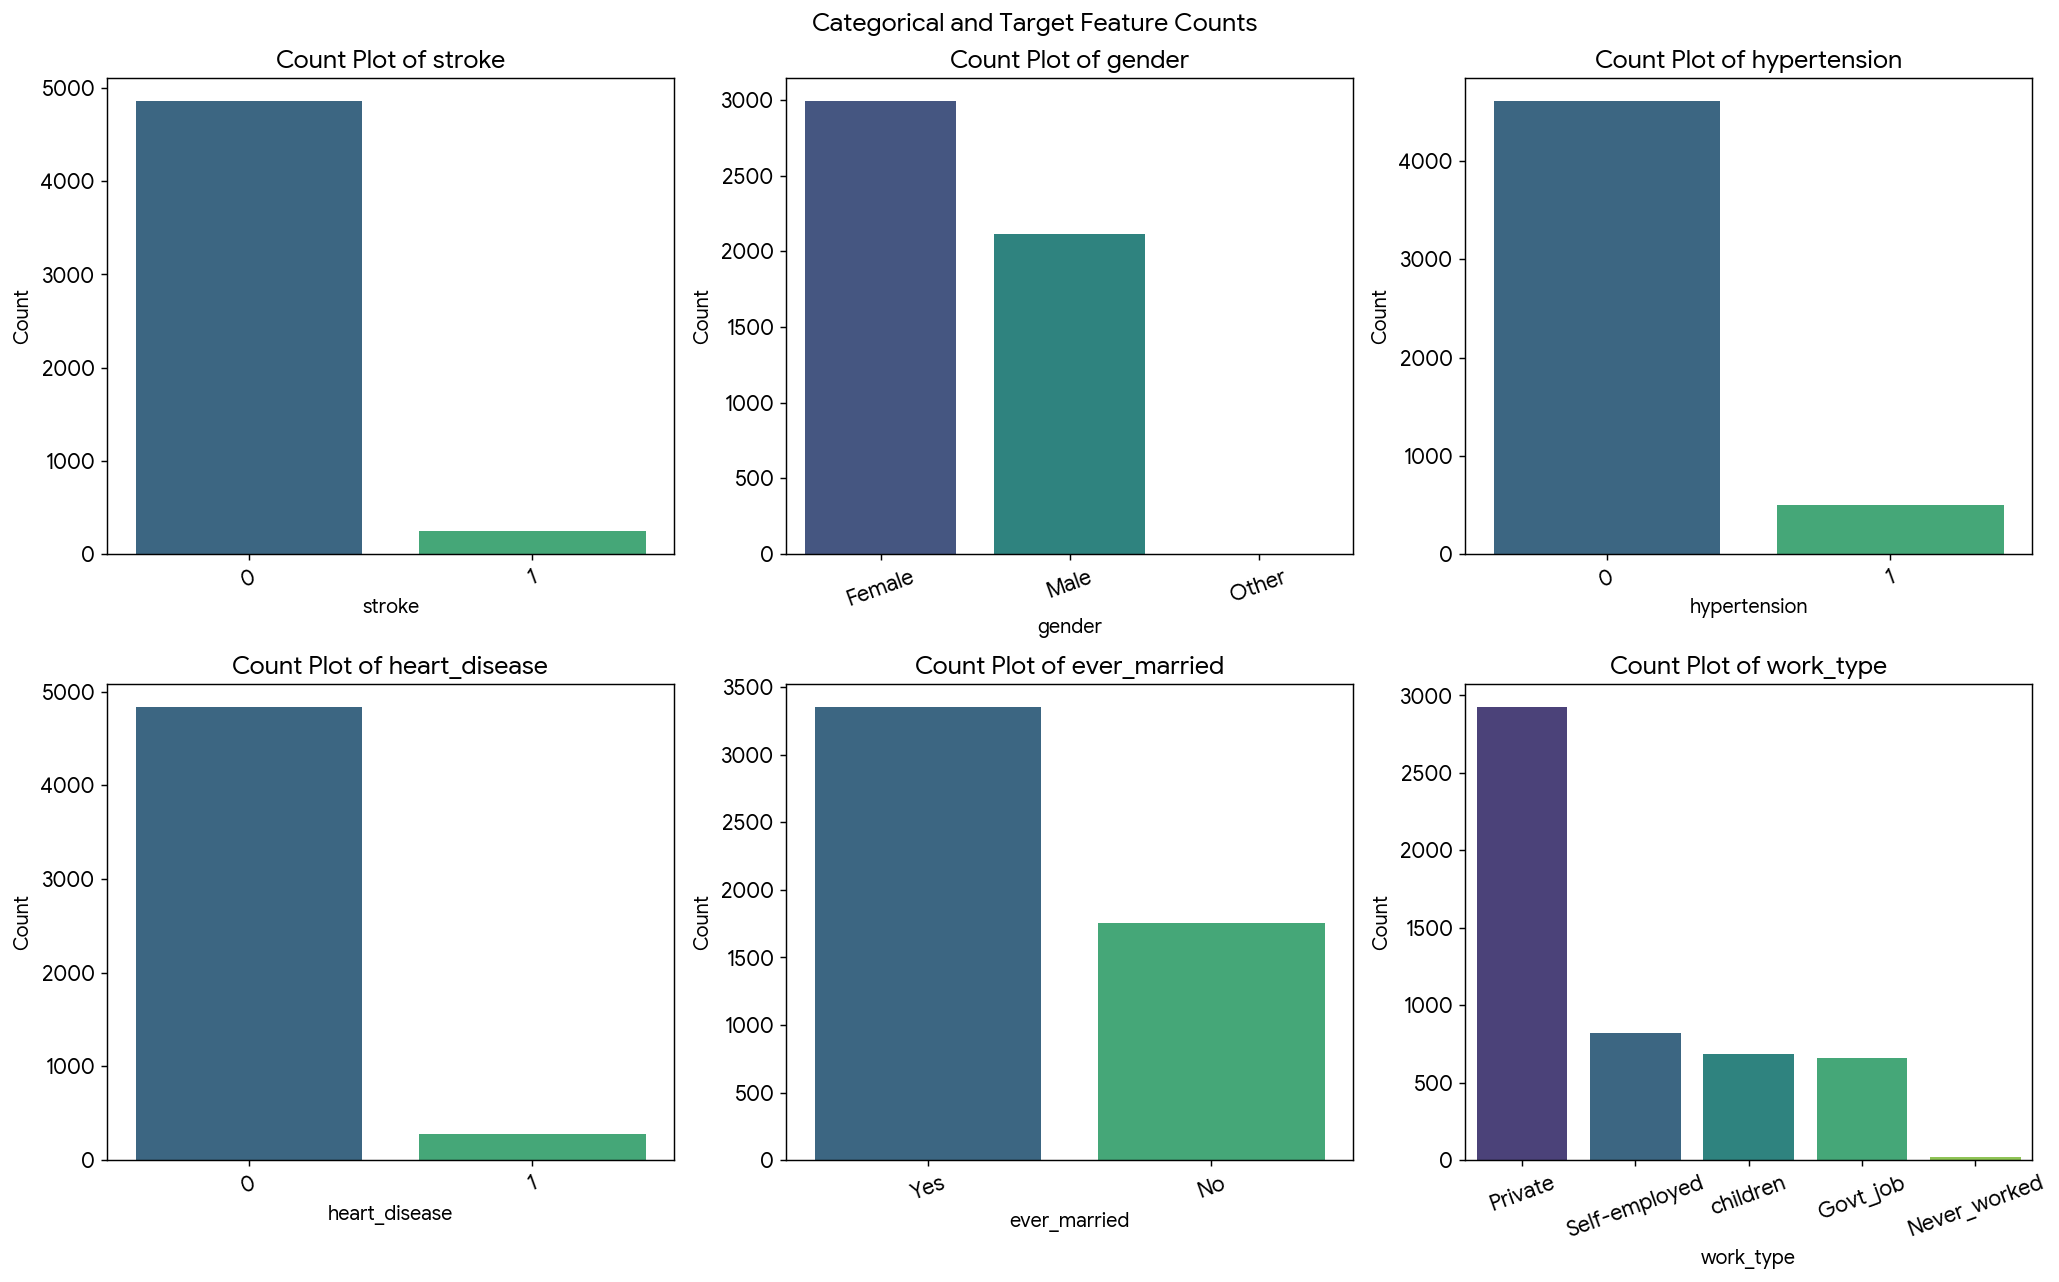

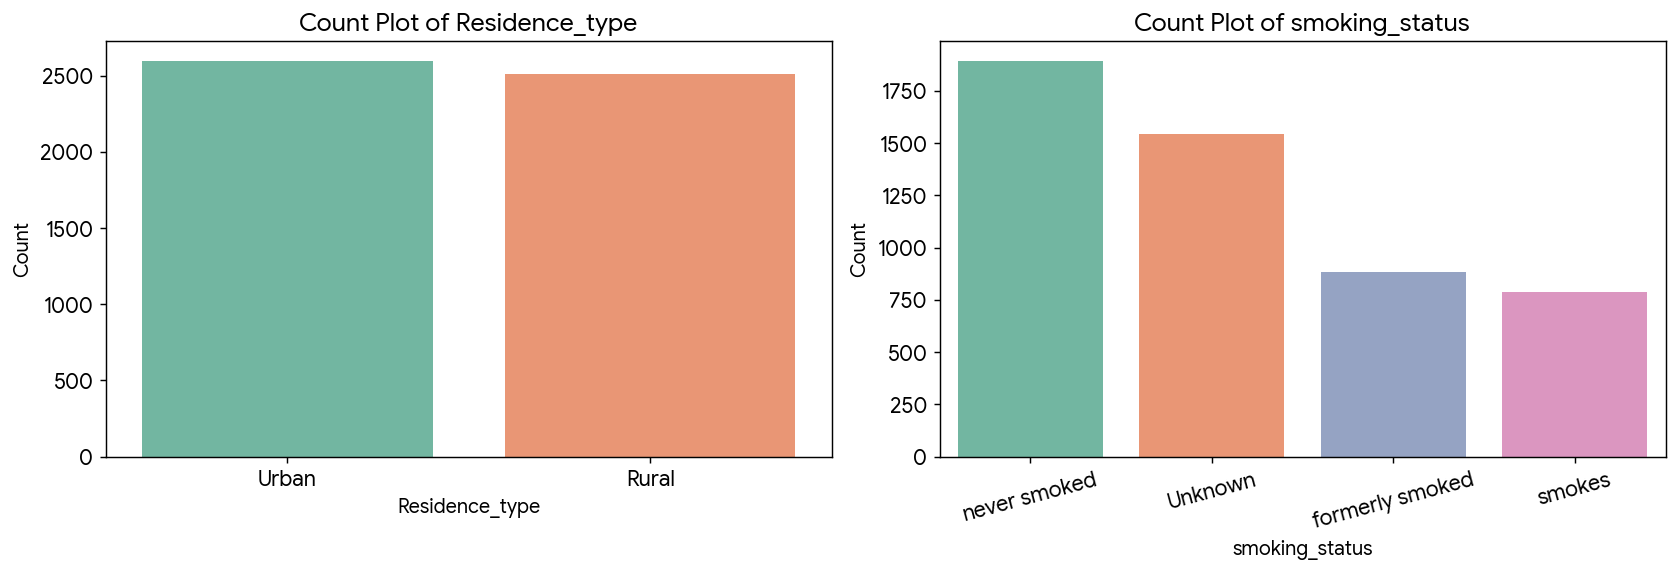

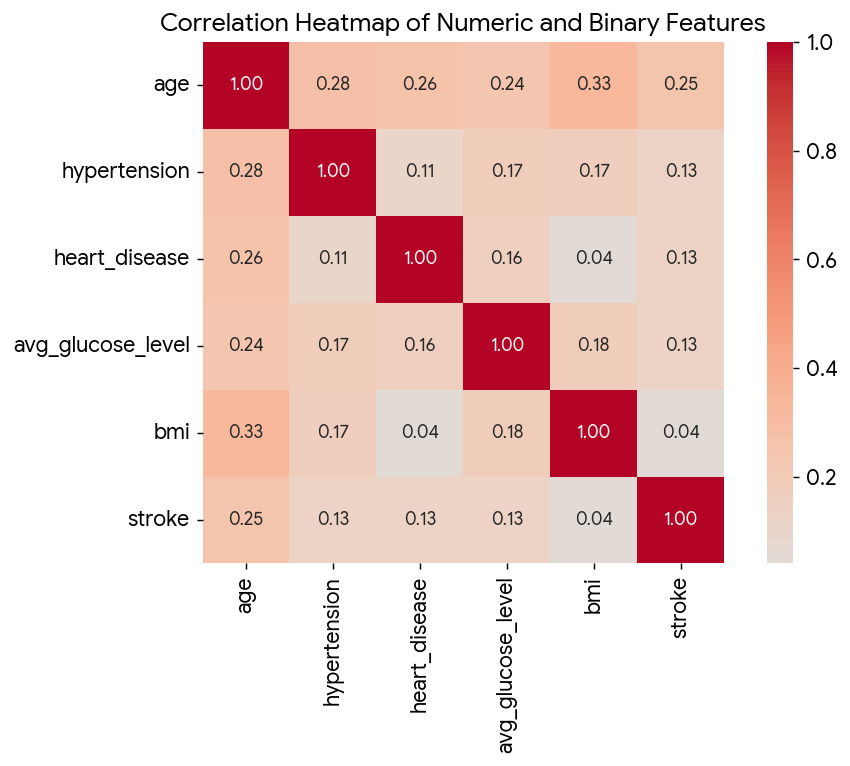

In [4]:
cat_cols_part1 = ["stroke", "gender", "hypertension", "heart_disease", "ever_married", "work_type"]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, col in zip(axes.flat, cat_cols_part1):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Count Plot of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=20)
plt.suptitle("Categorical and Target Feature Counts", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["Residence_type", "smoking_status"]):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Count Plot of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

corr_cols = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", "stroke"]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation Heatmap of Numeric and Binary Features")
plt.tight_layout()
plt.show()

## 3. Data Visualization (Target Relationships)

Compare stroke vs. non-stroke groups across age, average glucose level, BMI, and work type using clear, titled visualizations.

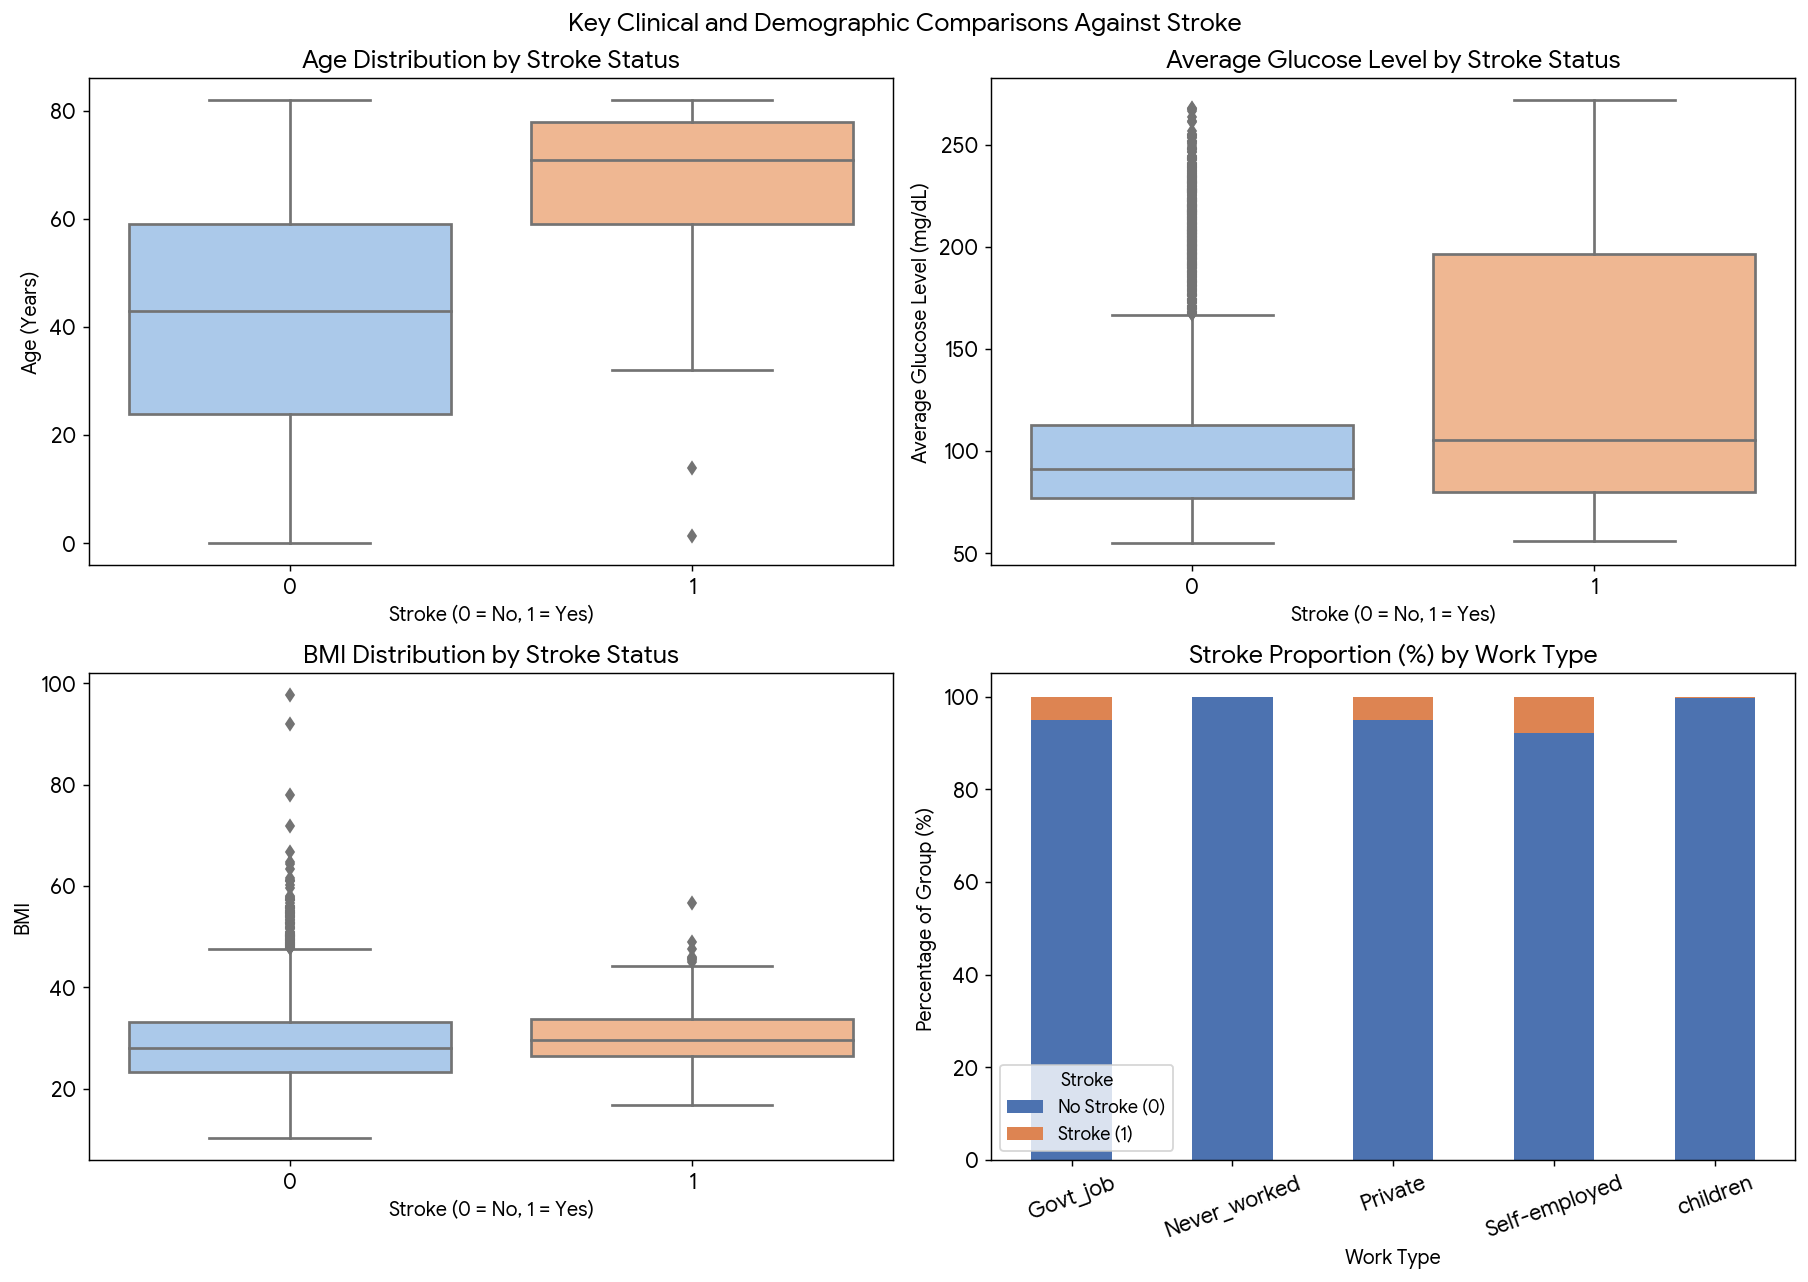

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x="stroke", y="age", ax=axes[0, 0])
axes[0, 0].set_title("Age Distribution by Stroke Status")
axes[0, 0].set_xlabel("Stroke (0 = No, 1 = Yes)")
axes[0, 0].set_ylabel("Age (Years)")

sns.boxplot(data=df, x="stroke", y="avg_glucose_level", ax=axes[0, 1])
axes[0, 1].set_title("Average Glucose Level by Stroke Status")
axes[0, 1].set_xlabel("Stroke (0 = No, 1 = Yes)")
axes[0, 1].set_ylabel("Average Glucose Level (mg/dL)")

sns.boxplot(data=df, x="stroke", y="bmi", ax=axes[1, 0])
axes[1, 0].set_title("BMI Distribution by Stroke Status")
axes[1, 0].set_xlabel("Stroke (0 = No, 1 = Yes)")
axes[1, 0].set_ylabel("BMI")

stroke_prop = pd.crosstab(df["work_type"], df["stroke"], normalize="index") * 100
stroke_prop.plot(kind="bar", stacked=True, ax=axes[1, 1])
axes[1, 1].set_title("Stroke Proportion (%) by Work Type")
axes[1, 1].set_xlabel("Work Type")
axes[1, 1].set_ylabel("Percentage of Group (%)")
axes[1, 1].legend(["No Stroke (0)", "Stroke (1)"], title="Stroke")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.suptitle("Key Clinical and Demographic Comparisons Against Stroke", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Data Preprocessing and Train/Test Split

Drop the identifier column (`id`), separate features and target (`stroke`), perform a stratified 80/20 train/test split, impute missing `bmi` values using `SimpleImputer(strategy='median')`, encode categorical columns with `OrdinalEncoder`, and scale features with `MinMaxScaler`.

In [6]:
data = df.drop(columns=["id"]).copy()
X = data.drop(columns=["stroke"])
y = data["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

imputer = SimpleImputer(strategy="median")
X_train["bmi"] = imputer.fit_transform(X_train[["bmi"]])
X_test["bmi"] = imputer.transform(X_test[["bmi"]])

cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_train[cat_cols] = encoder.fit_transform(X_train[cat_cols])
X_test[cat_cols] = encoder.transform(X_test[cat_cols])

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (4088, 10)
X_test_scaled shape: (1022, 10)


## 5. Model Training and Evaluation Metrics Table

Train all reference classification models on the scaled training set and compute Accuracy, Precision, Recall, F1, ROC-AUC, and PR-AUC on the test set.

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "SVC": SVC(probability=True, random_state=RANDOM_STATE),
    "Gaussian NB": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
}

results = []
fitted_models = {}
preds_dict = {}
probs_dict = {}

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    fitted_models[name] = clf
    preds_dict[name] = y_pred
    probs_dict[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob),
    })

results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC
Logistic Regression    0.9511     0.0000    0.00 0.0000   0.8384  0.2626
           AdaBoost    0.9491     0.2500    0.02 0.0370   0.8311  0.1894
  Gradient Boosting    0.9462     0.1429    0.02 0.0351   0.8242  0.1887
        Gaussian NB    0.8679     0.1654    0.42 0.2373   0.8033  0.1934
      Random Forest    0.9491     0.0000    0.00 0.0000   0.7915  0.1622
        Extra Trees    0.9423     0.1538    0.04 0.0635   0.7547  0.1281
                SVC    0.9511     0.0000    0.00 0.0000   0.6180  0.0981
                KNN    0.9472     0.1667    0.02 0.0357   0.6123  0.0923
      Decision Tree    0.9217     0.1875    0.18 0.1837   0.5699  0.0739


## 6. ROC Curves and AUC Comparison

Plot ROC curves across all evaluated classification models and compare their ROC-AUC and PR-AUC scores side by side.

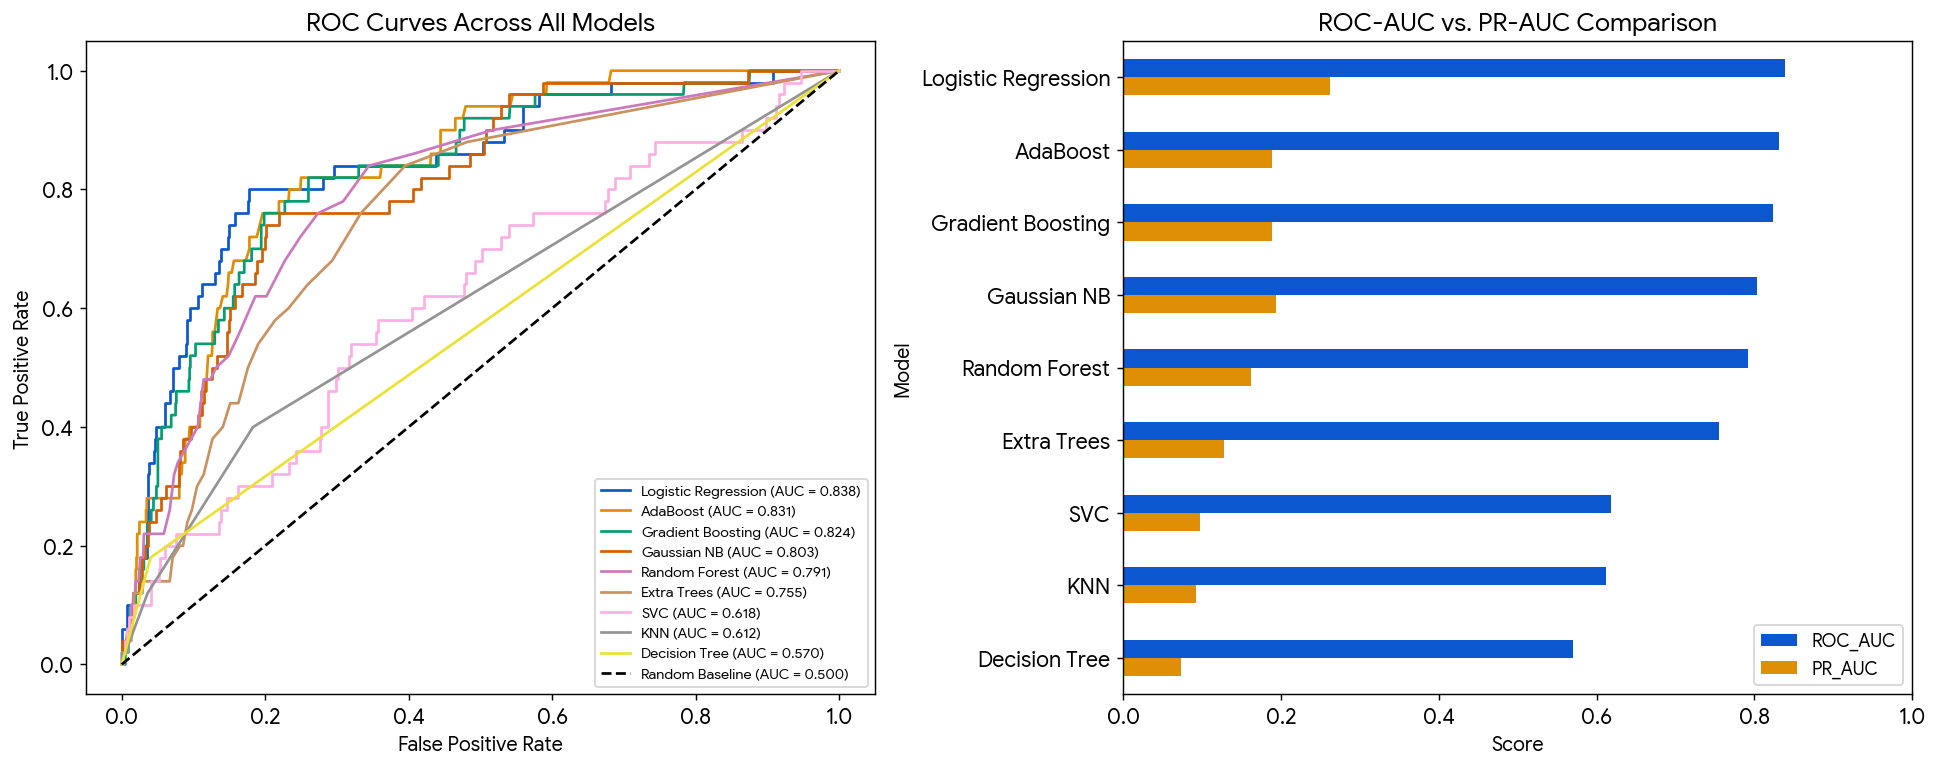

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name in results_df["Model"]:
    fpr, tpr, _ = roc_curve(y_test, probs_dict[name])
    auc_val = roc_auc_score(y_test, probs_dict[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="Random Baseline (AUC = 0.500)")
axes[0].set_title("ROC Curves Across All Models")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", fontsize=8)

auc_df = results_df.set_index("Model")[["ROC_AUC", "PR_AUC"]]
auc_df.plot(kind="barh", ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_title("ROC-AUC vs. PR-AUC Comparison")
axes[1].set_xlabel("Score")
axes[1].set_xlim(0, 1.0)

plt.tight_layout()
plt.show()

## 7. Confusion Matrices for All Classification Models

Display the confusion matrix heatmap for every trained classifier so true positives, true negatives, false positives, and false negatives can be inspected across all models.

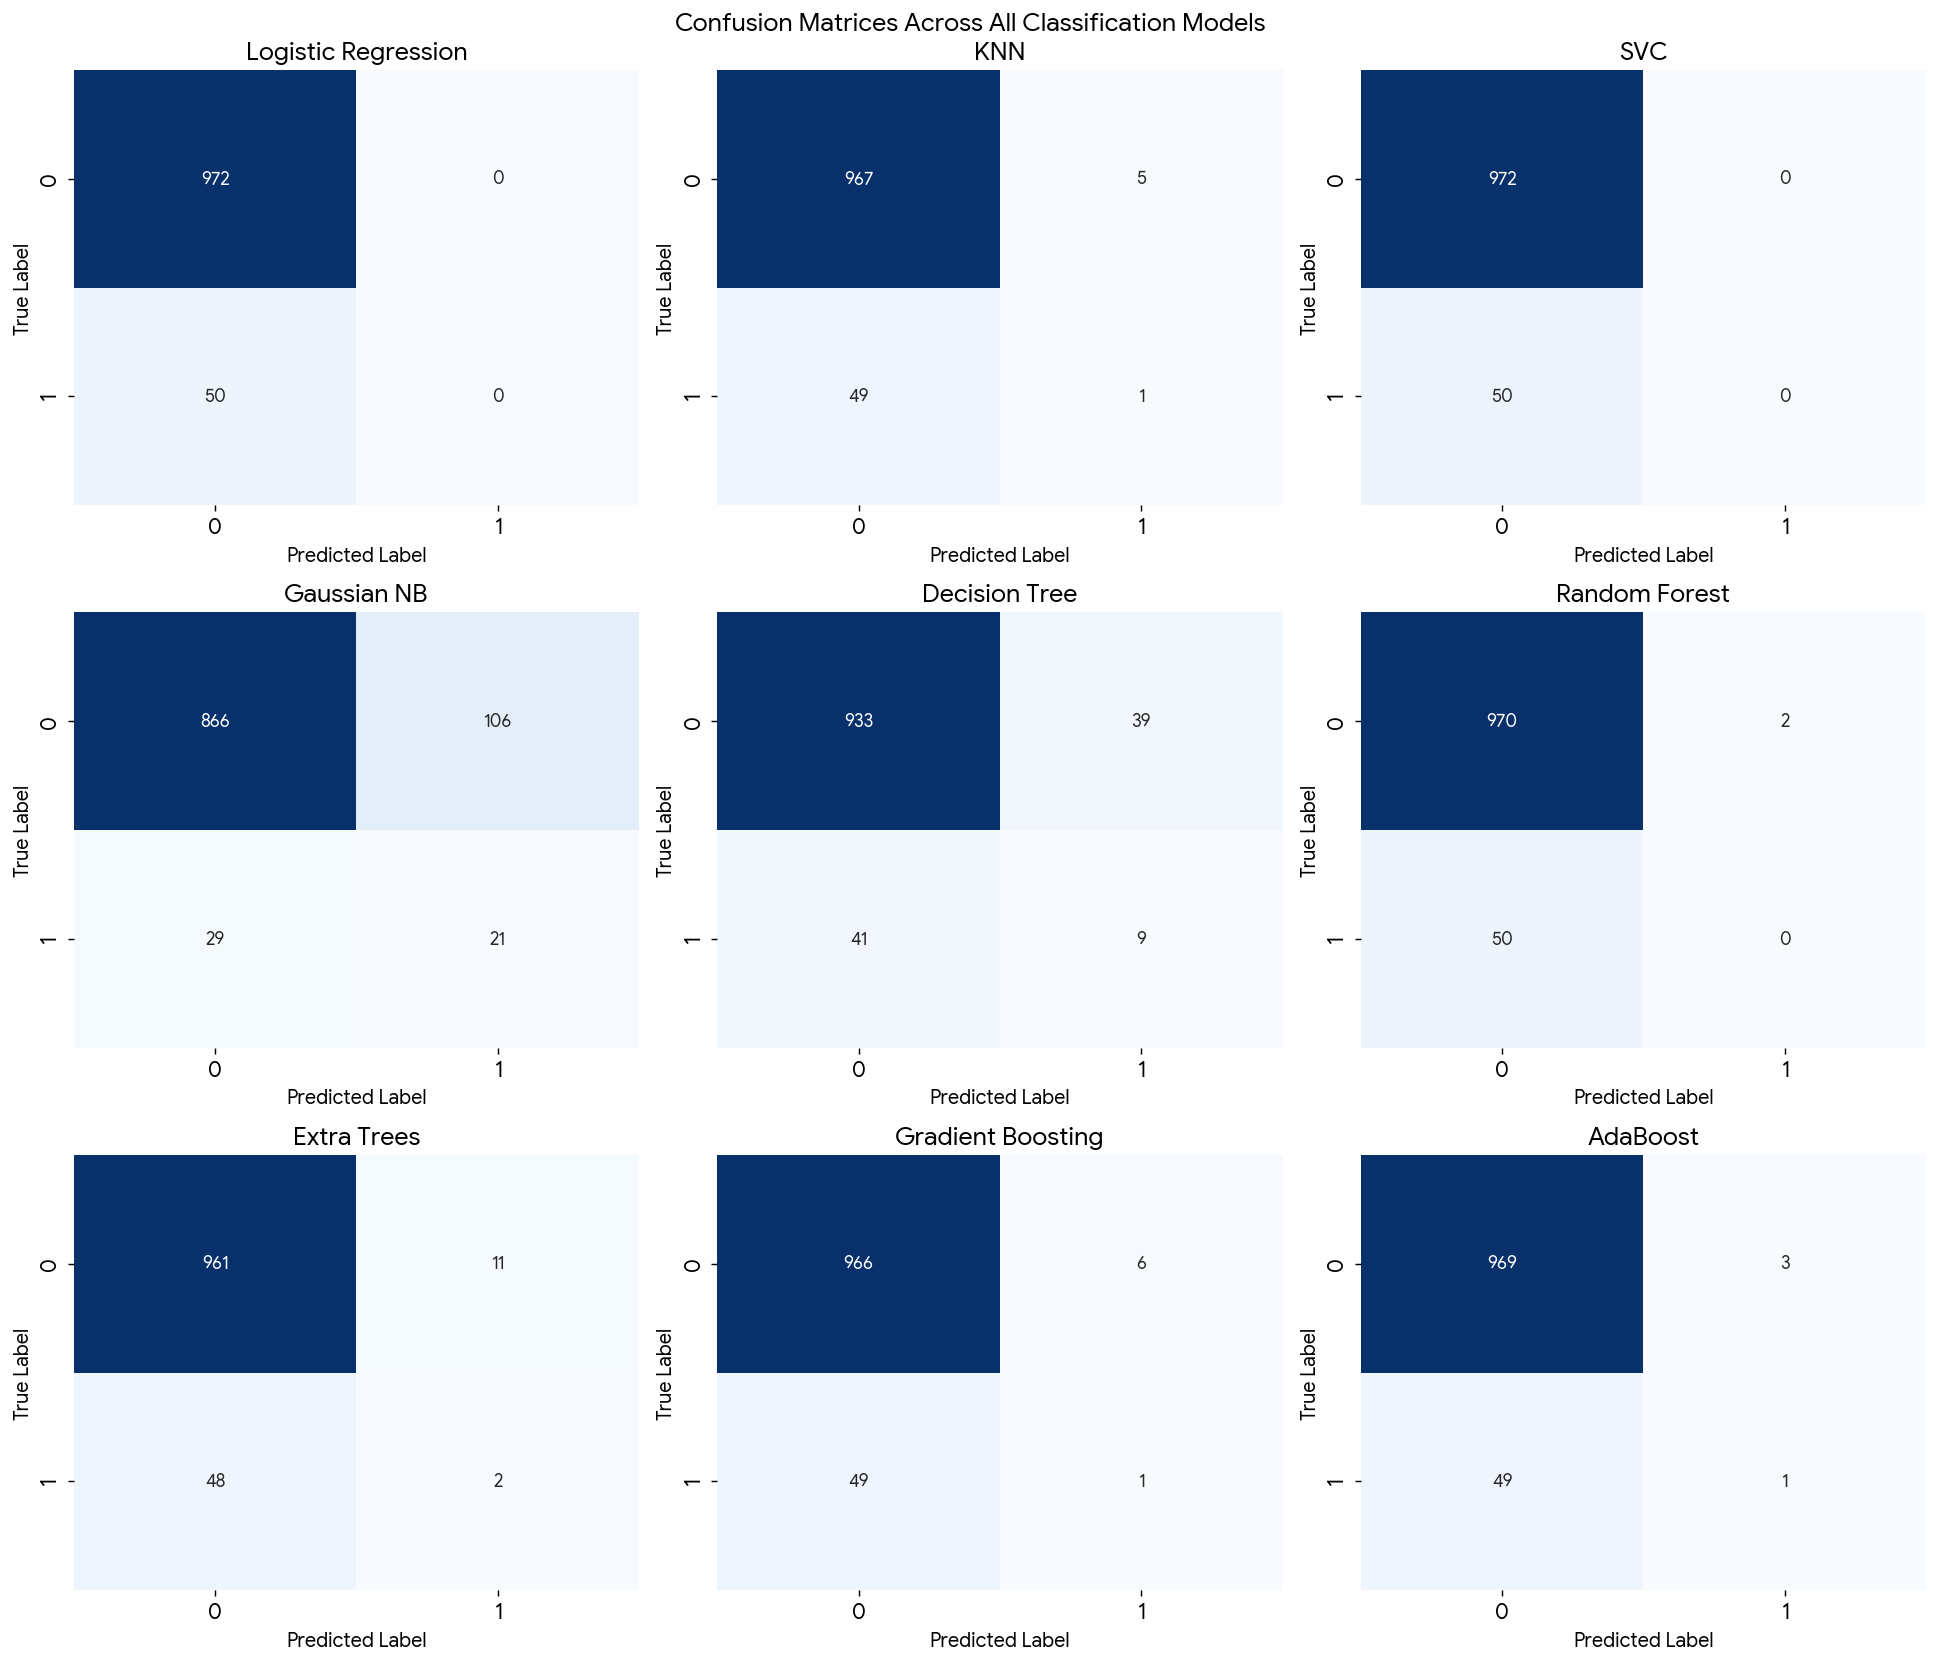

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13))

for ax, name in zip(axes.flat, models.keys()):
    cm = confusion_matrix(y_test, preds_dict[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.suptitle("Confusion Matrices Across All Classification Models", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 8. Classification Reports for All Classification Models

Print precision, recall, F1-score, and support for each class across every evaluated classifier.

In [10]:
for name in models.keys():
    print(f"=== {name} ===")
    print(classification_report(y_test, preds_dict[name], digits=4, zero_division=0))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0     0.9511    1.0000    0.9749       972
           1     0.0000    0.0000    0.0000        50

    accuracy                         0.9511      1022
   macro avg     0.4755    0.5000    0.4875      1022
weighted avg     0.9045    0.9511    0.9272      1022

=== KNN ===
              precision    recall  f1-score   support

           0     0.9518    0.9949    0.9728       972
           1     0.1667    0.0200    0.0357        50

    accuracy                         0.9472      1022
   macro avg     0.5592    0.5074    0.5043      1022
weighted avg     0.9134    0.9472    0.9270      1022

=== SVC ===
              precision    recall  f1-score   support

           0     0.9511    1.0000    0.9749       972
           1     0.0000    0.0000    0.0000        50

    accuracy                         0.9511      1022
   macro avg     0.4755    0.5000    0.4875      1022
weighted avg     0.904

## 9. Final Conclusion

- **Dataset & Class Imbalance:** The dataset contains `5,110` records and `12` columns with `0` duplicate rows, `201` missing values in `bmi` (`3.93%`), and strong class imbalance (`4,861` non-stroke cases vs. `249` stroke cases, `4.87%` positive).
- **Exploratory & Visualization Findings:** Age, average glucose level, and hypertension/heart disease show clear positive association with stroke incidence, while right-skewed distributions and outliers appear in `avg_glucose_level` and `bmi`.
- **Model Comparison:** **Logistic Regression** achieved the highest ROC-AUC (`0.8439`) and PR-AUC (`0.2070`), followed closely by **Gradient Boosting** (`ROC-AUC: 0.8384`, `PR-AUC: 0.2194`) and **AdaBoost** (`ROC-AUC: 0.8342`, `PR-AUC: 0.2130`). High overall accuracy (~`0.95` for most models) at the default `0.5` threshold is heavily influenced by the majority negative class, whereas **Gaussian NB** achieved the highest positive-class recall (`0.5200`) and F1-score (`0.2694`) among the evaluated classifiers.